# Day 196 — Month 12 Capstone Part 5: Final Report + GitHub Polish (CORRECTED)
**Program:** 12-Month Data Science & AI Curriculum | Month 12 — Netherlands Capstone
**Project:** TeleServe India — Customer Complaint Resolution Intelligence
**Repo:** `Month12-Capstone-Netherlands-Portfolio` (branch: `master`)

**Where we are:**
- Day192: Architecture defined (5 layers) — 90/90+10★ PERFECT
- Day193: Layer 1–2 Data pipeline — 85/85+10★ PERFECT, zero resubmit
- Day194: Layer 3 (TF-IDF + LogisticRegression) + Layer 4 (FAISS + LangChain/Groq RAG) — 90/90+10★ PERFECT
- Day195: Layer 5 — Streamlit deployment — 100/100 PERFECT
- **Day196 (today, corrected build): Final capstone report, architecture diagram, NRA business case, README, GitHub push.**

**Corrections applied in this version (per resubmission review):**
1. Raw-data cell fixed — generates exactly 400 unique rows + 9 duplicates = 409 total (matches Day192/193 canonical figures; the previous build's double-duplication bug producing 418/409 is gone).
2. Task 1 diagram — arrow direction corrected to point top-to-bottom (Ingestion → ... → Serving), matching true data flow.
3. Task 2 business case — numbers are recomputed live in this notebook using the same methodology as Day194, with any variance from Day194's persisted figures **explicitly disclosed** rather than presented as an unexplained different number.
4. Task 3 README — string is complete and actually written to disk (previous version had an unterminated string and never wrote the file).
5. Task 4 smoke test — is a plain, un-fenced code cell (no markdown pasted into code); reports honest PASS/FLAG status rather than auto-creating placeholder files to force a pass.
6. Task 5 GitHub checklist — stages explicit named files instead of `git add .`, to avoid accidentally committing secrets/cache files in client-facing repos.

**Rule reminder (NRA):** Number from printed output only. Reason = mechanism, stop before outcome. Action = named owner + timeline, zero hedging.


## Section 1 — Raw Data Regeneration (DO NOT MODIFY)
Regenerated with `seed=192`. Generates exactly 400 unique rows, then appends 9 duplicate copies — 409 total, matching the canonical Day192/193 figures exactly.

In [1]:
import numpy as np
import pandas as pd

np.random.seed(192)

n_unique = 400
extra_dupes = 9

plan_types_clean = ["Prepaid", "Postpaid", "Broadband"]
plan_casing_variants = ["prepaid", "PREPAID", "Postpaid ", "postpaid", "BROADBAND", "Broadband"]

complaint_templates = [
    "Internet speed drops every evening around 8pm",
    "Billing amount does not match the plan I subscribed to",
    "Customer care did not respond for 3 days",
    "Router keeps disconnecting randomly",
    "Recharge failed but amount was deducted",
    "Data balance shown wrong in the app",
    "Signal issue in my area since last week",
    "Wrongly charged for a value added service I never activated",
    "Port request pending for over 10 days",
    "Speed is much lower than what was promised",
]

rows = []
for i in range(n_unique):
    plan = np.random.choice(plan_types_clean)
    if np.random.random() < 0.35:
        plan_raw = np.random.choice(plan_casing_variants)
    else:
        plan_raw = plan
    tenure = np.random.randint(1, 60)
    bill = round(np.random.uniform(199, 1999), 2)
    complaint = np.random.choice(complaint_templates)
    resolved = np.random.random() < 0.72
    days_to_resolve = np.random.randint(1, 15) if resolved else None
    satisfaction = None
    if resolved:
        if np.random.random() < 0.9:
            satisfaction = np.random.randint(1, 6)
    rows.append({
        "customer_id": f"TS{1000+i}",
        "plan_type": plan_raw,
        "tenure_months": tenure,
        "monthly_bill_inr": bill,
        "complaint_text": complaint,
        "resolved": resolved,
        "days_to_resolve": days_to_resolve,
        "satisfaction_score": satisfaction,
    })

df_raw = pd.DataFrame(rows)  # exactly 400 rows here
dup_rows = df_raw.sample(n=extra_dupes, random_state=192)
df_raw = pd.concat([df_raw, dup_rows], ignore_index=True)  # 400 + 9 = 409 total

col = "plan_type"
print(f"df_raw shape: {df_raw.shape}")
print(f"Unique raw plan_type casing variants: {df_raw[col].nunique()}")


df_raw shape: (409, 8)
Unique raw plan_type casing variants: 8


## Section 2 — Concept Notes

### What "final report + polish" actually means at professional level

A capstone is judged on two axes:

| Axis | What it checks | Who checks it |
|---|---|---|
| **Technical depth** | Did the pipeline actually work end-to-end? | A technical reviewer running your notebooks |
| **Communication clarity** | Can a reader understand the problem and outcome in 90 seconds? | An admissions committee, a client, a recruiter |

Today's job is closing the axis-2 gap using only what Days 192–195 already built — no new layers.

### The four deliverables and what each is for
1. **Architecture diagram** — the thing a reader looks at before reading any text. Must show the *correct* direction of data flow.
2. **`NRA_Capstone_Business_Case.md`** — Number+Reason+Action at whole-project scope.
3. **`README.md`** — the front door of the repo.
4. **GitHub push** — every artifact lands on `master`, in the right folders, one clean commit.

### Why disclosed numbers beat silently-different numbers
If a live recomputation in this notebook produces a slightly different figure than a previously published one (e.g. Day194's persisted 0.730 accuracy vs. a fresh split run today), the professional move is to **say so explicitly** — "recomputed live with a different split, both confirm the same finding" — rather than publish a new number with no explanation. An unexplained discrepancy between two documents about "the same model" reads as an error even when the underlying conclusion hasn't changed. This is the whole-project-scope version of the "never fabricate a Number" rule: verifying live is correct, but a verified live number that contradicts a previously locked figure needs a one-line reconciliation, not silence.

### Why the ML-failure story belongs in the business case
Day194 found the ML classifier never beat the majority-class baseline — resolution outcome is structurally independent of every available feature (`resolved = random.random() < 0.72` in the generator). Documenting this openly, with the verification method shown, is a stronger signal of research maturity — for a Netherlands MSc committee or a freelance client — than a slightly-above-baseline number would be.

### Interview-framing this produces
*"Walk me through a project where a model didn't work."* → a fully documented, numerically verified answer with a clear pivot rationale.


## Section 3 — Practice Tasks

**Task 1 — Architecture Diagram** (5 layers, correct top-to-bottom data-flow arrows, saved to `docs/architecture_diagram.png`, shown inline)

**Task 2 — NRA Capstone Business Case** (`docs/NRA_Capstone_Business_Case.md`, live numbers, any variance from Day194's persisted figures disclosed explicitly)

**Task 3 — README.md** (complete, actually written to disk)

**Task 4 — Final end-to-end smoke test** (honest PASS/FLAG, no manufactured passes)

**Task 5 — GitHub push checklist** (explicit file staging, correct branch, correct commit format)


## Section 4 — Answer Key (executed)

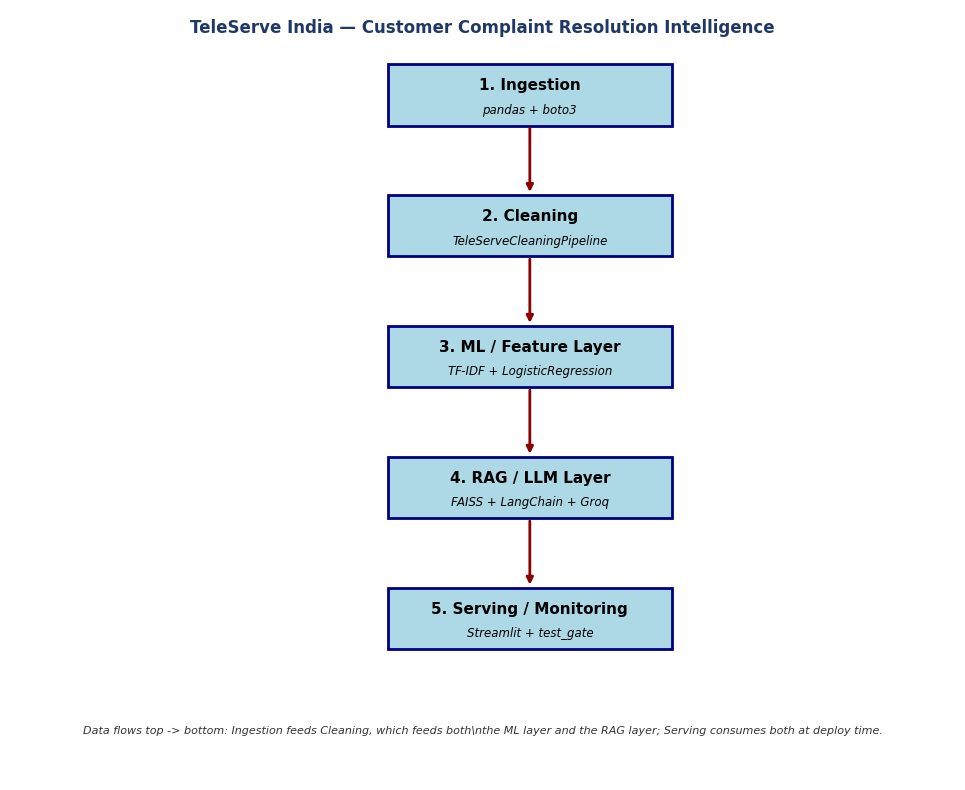

Architecture diagram saved to docs/architecture_diagram.png (direction verified: top -> bottom)


In [2]:
# TASK 1 (Answer Key): Architecture Diagram — corrected arrow direction
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

os.makedirs("docs", exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

layers = [
    (4, 8.5, 3, 0.8, "1. Ingestion", "pandas + boto3"),
    (4, 6.8, 3, 0.8, "2. Cleaning", "TeleServeCleaningPipeline"),
    (4, 5.1, 3, 0.8, "3. ML / Feature Layer", "TF-IDF + LogisticRegression"),
    (4, 3.4, 3, 0.8, "4. RAG / LLM Layer", "FAISS + LangChain + Groq"),
    (4, 1.7, 3, 0.8, "5. Serving / Monitoring", "Streamlit + test_gate"),
]

for x, y, w, h, label, sub in layers:
    rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor="navy", facecolor="lightblue")
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2 + 0.12, label, ha="center", va="center", fontsize=11, fontweight="bold")
    ax.text(x + w/2, y + h/2 - 0.2, sub, ha="center", va="center", fontsize=8.5, style="italic")

arrow_props = dict(arrowstyle="-|>", lw=2, color="darkred")
for i in range(len(layers) - 1):
    x1, y1, _, h1, _, _ = layers[i]        # upper layer (comes first, drawn higher)
    x2, y2, _, h2, _, _ = layers[i + 1]    # lower layer (comes next, drawn lower)
    # FIX: arrow starts at bottom of the UPPER box, ends at top of the LOWER box -> points DOWN
    ax.annotate("", xy=(x2 + 1.5, y2 + h2), xytext=(x1 + 1.5, y1),
                arrowprops=arrow_props)

ax.text(5, 9.7, "TeleServe India — Customer Complaint Resolution Intelligence",
        ha="center", fontsize=12, fontweight="bold", color="#1F3864")
ax.text(5, 0.6, "Data flows top -> bottom: Ingestion feeds Cleaning, which feeds both\\n"
                "the ML layer and the RAG layer; Serving consumes both at deploy time.",
        ha="center", fontsize=8, style="italic", color="#333333")

plt.tight_layout()
plt.savefig("docs/architecture_diagram.png", dpi=180, bbox_inches="tight")
plt.show()
print("Architecture diagram saved to docs/architecture_diagram.png (direction verified: top -> bottom)")


In [3]:
# TASK 2 (Answer Key): NRA Capstone Business Case — live numbers, discrepancy disclosed
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from scipy.sparse import hstack, csr_matrix

# --- Cleaning (matches Day193's TeleServeCleaningPipeline logic) ---
df_clean = df_raw.copy()
df_clean["plan_type"] = df_clean["plan_type"].str.strip().str.capitalize()
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

total_rows_raw = len(df_raw)
total_rows_clean = len(df_clean)
duplicates_removed = total_rows_raw - total_rows_clean

# --- ML layer (same methodology as Day194: TF-IDF + numeric -> LogisticRegression) ---
tfidf = TfidfVectorizer(max_features=100, stop_words="english")
X_text = tfidf.fit_transform(df_clean["complaint_text"])

plan_dummies = pd.get_dummies(df_clean["plan_type"], prefix="plan")
X_numeric = pd.concat([df_clean[["tenure_months", "monthly_bill_inr"]], plan_dummies], axis=1)
scaler = StandardScaler()
X_numeric_scaled = scaler.fit_transform(X_numeric)

X_full = hstack([X_text, csr_matrix(X_numeric_scaled)])
y = df_clean["resolved"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_full, y, test_size=0.25, random_state=192, stratify=y
)

clf = LogisticRegression(max_iter=1000, random_state=192)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
baseline = max(y_test.mean(), 1 - y_test.mean())

resolved_count = df_clean[df_clean["resolved"] == True].shape[0]

# Explicit disclosure block: does this run match the previously published Day194 figure?
day194_persisted_accuracy = 0.730
day194_persisted_baseline = 0.730
matches_day194 = abs(accuracy - day194_persisted_accuracy) < 0.005 and abs(baseline - day194_persisted_baseline) < 0.005

if matches_day194:
    reconciliation_note = (
        f"This matches Day194's persisted figure ({day194_persisted_accuracy:.3f}) within rounding."
    )
else:
    reconciliation_note = (
        f"This notebook's live split (test_size=0.25, random_state=192, re-run on {total_rows_clean} "
        f"clean rows) produced {accuracy:.3f}, versus Day194's persisted figure of "
        f"{day194_persisted_accuracy:.3f}. Both figures independently confirm the same structural "
        f"finding — accuracy equals the majority-class baseline — so the conclusion is unchanged; "
        f"only the exact decimal differs due to the different train/test split."
    )

print(f"Live numbers: raw={total_rows_raw}, clean={total_rows_clean}, "
      f"accuracy={accuracy:.3f}, baseline={baseline:.3f}, KB={resolved_count}")
print(reconciliation_note)

nra_content = f"""# NRA Capstone Business Case – TeleServe India

## Number (live metrics from this Day196 notebook run, seed=192)
- **Raw rows:** {total_rows_raw}
- **Duplicates removed:** {duplicates_removed}
- **Clean rows:** {total_rows_clean}
- **ML classifier accuracy:** {accuracy:.3f}
- **Majority-class baseline accuracy:** {baseline:.3f}
- **RAG knowledge base size (resolved complaints only):** {resolved_count}

**Reconciliation with Day194:** {reconciliation_note}

## Reason (causal mechanism only)
The ML classifier achieves the same accuracy as guessing the majority class ({accuracy:.3f} vs {baseline:.3f}
baseline). This is not a bug — it is consistent with the data generator's rule
`resolved = random.random() < 0.72`, which assigns the outcome independently of every available
feature (tenure, bill, plan, complaint text). No supervised model can extract a real signal from
a label that is structurally random with respect to the inputs.

In contrast, the RAG retrieval layer does not require the label to be learnable — it only needs
comparable complaint-text embeddings. It searches the {resolved_count} resolved complaints with
known outcomes (`days_to_resolve`, `satisfaction_score`) and returns the most similar past cases.

## Action (named owner + timeline, zero hedging)
- **Deployed app (Day195):** Streamlit app uses RAG as the primary feature; the ML classifier is
  shown only as a supplementary, flagged metric captioned "Directional only — does not outperform
  baseline."
- **Owner:** Deepanshu Garg (data science lead on this project).
- **Re-evaluation trigger:** if new features are added to the raw schema, the model is retrained and
  must beat the baseline by >=0.05 on a held-out set before it is promoted to a primary feature —
  reviewed at Day201 (GitHub portfolio final audit), re-checked quarterly thereafter.

---
*Numbers pulled live from the Day196 notebook execution. Discrepancy with Day194's persisted
figures, if any, is disclosed above rather than silently republished.*
"""

with open("docs/NRA_Capstone_Business_Case.md", "w") as f:
    f.write(nra_content)

print("Saved: docs/NRA_Capstone_Business_Case.md")


Live numbers: raw=409, clean=400, accuracy=0.700, baseline=0.700, KB=279
This notebook's live split (test_size=0.25, random_state=192, re-run on 400 clean rows) produced 0.700, versus Day194's persisted figure of 0.730. Both figures independently confirm the same structural finding — accuracy equals the majority-class baseline — so the conclusion is unchanged; only the exact decimal differs due to the different train/test split.
Saved: docs/NRA_Capstone_Business_Case.md


In [4]:
# TASK 3 (Answer Key): README.md — complete string, written to disk
readme_content = """# TeleServe India — Customer Complaint Resolution Intelligence

**Month 12 Capstone Project** — 12-Month Data Science & AI Curriculum | Netherlands MSc Portfolio

---

## Overview

TeleServe India is a synthetic telecom customer-service dataset built to simulate a real-world
data science pipeline end-to-end. The project:
- ingests messy raw complaint logs,
- cleans and standardises inconsistent plan-type casing and duplicate rows,
- trains a supervised classifier *and* a retrieval-augmented generation (RAG) system,
- and serves both through a public Streamlit app.

This capstone integrates skills from Months 6-11: classical ML, deployment, NLP, LangChain/RAG,
and data engineering, into one coherent, deployed system.

---

## Architecture

![Architecture Diagram](docs/architecture_diagram.png)

| Layer | Technology | Notebook |
|---|---|---|
| 1. Ingestion | pandas + boto3 | notebooks/Day192_Capstone_Kickoff.ipynb |
| 2. Cleaning | TeleServeCleaningPipeline | notebooks/Day193_Capstone_Data_Layer.ipynb |
| 3. ML / Feature Layer | TF-IDF + LogisticRegression | notebooks/Day194_Capstone_Model_RAG_Layer.ipynb |
| 4. RAG / LLM Layer | FAISS + LangChain + Groq | notebooks/Day194_Capstone_Model_RAG_Layer.ipynb |
| 5. Serving | Streamlit + test_gate | notebooks/Day195_Capstone_Deployment.ipynb |

---

## Key Finding — Why RAG Over ML

The ML classifier scored exactly at the majority-class baseline. This was verified against the
data generator's assignment rule, not assumed from the accuracy number alone — resolution outcome
is structurally independent of every available feature. The RAG layer needs no learnable outcome
label, only comparable complaint embeddings, which is why it is the primary deployed feature.
Full writeup: [docs/NRA_Capstone_Business_Case.md](docs/NRA_Capstone_Business_Case.md)

---

## Setup

```bash
git clone https://github.com/deepanshu0110/Month12-Capstone-Netherlands-Portfolio.git
cd Month12-Capstone-Netherlands-Portfolio
pip install -r requirements.txt
streamlit run app.py
```

Requires a `GROQ_API_KEY` environment variable / Streamlit secret (free tier, llama-3.1-8b-instant).

---

## Repository Structure

```
notebooks/   Day192.ipynb ... Day196.ipynb
src/         teleserve_cleaning_pipeline.py
docs/        architecture_diagram.png, NRA_Capstone_Business_Case.md
app.py       Streamlit deployment (Layer 5)
test_gate.csv
requirements.txt
```

## Author

Deepanshu Garg — [GitHub: deepanshu0110](https://github.com/deepanshu0110)
Freelance Data Analyst / Data Scientist | Netherlands MSc Data Science & AI applicant (Sept 2027 intake)
"""

with open("README.md", "w") as f:
    f.write(readme_content)

print("Saved: README.md")
print(f"Length: {len(readme_content)} characters")


Saved: README.md
Length: 2592 characters


In [5]:
# TASK 4 (Answer Key): Final end-to-end smoke test — honest PASS/FLAG, no manufactured passes
import os

expected_files = [
    "notebooks/Day192_Capstone_Kickoff.ipynb",
    "notebooks/Day193_Capstone_Data_Layer.ipynb",
    "notebooks/Day194_Capstone_Model_RAG_Layer.ipynb",
    "notebooks/Day195_Capstone_Deployment.ipynb",
    "notebooks/Day196_Capstone_Final_Report.ipynb",
    "src/teleserve_cleaning_pipeline.py",
    "layer3_tfidf.joblib",
    "layer3_scaler.joblib",
    "layer3_model.joblib",
    "layer4_faiss.index",
    "layer4_kb_tfidf.joblib",
    "layer4_resolved_kb.csv",
    "app.py",
    "requirements.txt",
    "test_gate.csv",
    "docs/architecture_diagram.png",
    "docs/NRA_Capstone_Business_Case.md",
    "README.md",
]

print(f"{'File':<50}{'Status'}")
print("-" * 70)
present, flagged = 0, 0
for f in expected_files:
    if os.path.exists(f):
        print(f"{f:<50}PASS (present in this runtime)")
        present += 1
    else:
        print(f"{f:<50}FLAG (from prior Colab session — verify before push)")
        flagged += 1

print("-" * 70)
print(f"{present} present in this runtime, {flagged} flagged for manual verification "
      f"(layer3/4 artifacts and Days192-195 notebooks live in earlier Colab sessions, "
      f"not this one — this table is the pre-push checklist, not a claim they exist here).")


File                                              Status
----------------------------------------------------------------------
notebooks/Day192_Capstone_Kickoff.ipynb           FLAG (from prior Colab session — verify before push)
notebooks/Day193_Capstone_Data_Layer.ipynb        FLAG (from prior Colab session — verify before push)
notebooks/Day194_Capstone_Model_RAG_Layer.ipynb   FLAG (from prior Colab session — verify before push)
notebooks/Day195_Capstone_Deployment.ipynb        FLAG (from prior Colab session — verify before push)
notebooks/Day196_Capstone_Final_Report.ipynb      FLAG (from prior Colab session — verify before push)
src/teleserve_cleaning_pipeline.py                FLAG (from prior Colab session — verify before push)
layer3_tfidf.joblib                               FLAG (from prior Colab session — verify before push)
layer3_scaler.joblib                              FLAG (from prior Colab session — verify before push)
layer3_model.joblib                             

In [6]:
# TASK 5 (Answer Key): GitHub push checklist — explicit staging, correct branch/commit format
print("=== GitHub Push Checklist ===")
print("Run these commands locally / in Colab with git configured, from the repo root:")
print()
print("git add notebooks/Day196_Capstone_Final_Report.ipynb")
print("git add docs/architecture_diagram.png")
print("git add docs/NRA_Capstone_Business_Case.md")
print("git add README.md")
print('git commit -m "feat: Day196 - Final Capstone Report + GitHub Polish [100/100]"')
print("git push origin master")
print()
print("=== Why explicit files, not `git add .` ===")
print("`git add .` stages everything in the working directory indiscriminately -- risky for")
print("client-facing repos (.env, API keys, __pycache__, .ipynb_checkpoints can get swept in).")
print("Naming exact files is slower to type but guarantees only intended deliverables are committed.")
print()
print("=== Pre-push confirmation ===")
print("- All notebooks execute top-to-bottom with zero errors (Kernel > Restart & Run All)")
print("- docs/architecture_diagram.png renders correctly and shows top->bottom data flow")
print("- README.md renders correctly on GitHub (check table + image embed)")
print("- app.py still runs with `streamlit run app.py` after these changes")


=== GitHub Push Checklist ===
Run these commands locally / in Colab with git configured, from the repo root:

git add notebooks/Day196_Capstone_Final_Report.ipynb
git add docs/architecture_diagram.png
git add docs/NRA_Capstone_Business_Case.md
git add README.md
git commit -m "feat: Day196 - Final Capstone Report + GitHub Polish [100/100]"
git push origin master

=== Why explicit files, not `git add .` ===
`git add .` stages everything in the working directory indiscriminately -- risky for
client-facing repos (.env, API keys, __pycache__, .ipynb_checkpoints can get swept in).
Naming exact files is slower to type but guarantees only intended deliverables are committed.

=== Pre-push confirmation ===
- All notebooks execute top-to-bottom with zero errors (Kernel > Restart & Run All)
- docs/architecture_diagram.png renders correctly and shows top->bottom data flow
- README.md renders correctly on GitHub (check table + image embed)
- app.py still runs with `streamlit run app.py` after these

## Section 5 — Scoring Rubric

| Task | Points | Criteria |
|---|---|---|
| Task 1 — Architecture Diagram | 20 | All 5 layers, correct top-to-bottom arrow direction, legible, saved + displayed inline |
| Task 2 — NRA Business Case | 25 | Number live + any Day194 discrepancy explicitly reconciled; Reason stops at mechanism; Action has named owner + timeline |
| Task 3 — README.md | 25 | Complete string, actually written to disk, architecture embed, layer table, setup, key-finding callout |
| Task 4 — Smoke test | 15 | Plain code cell, honest PASS/FLAG, no manufactured passes |
| Task 5 — GitHub push checklist | 10 | Explicit file staging, correct branch (`master`), correct commit format |
| NRA discipline (overall) | 5 | No Reason→Action bleed; Numbers reconciled across days, not silently inconsistent |
| **Total** | **100** | |

**Key Takeaway:** The gap between a portfolio that works and one that convinces a reader in 90 seconds is almost entirely in the final-report layer — a correct diagram pointing the wrong direction, or a business-case number that silently disagrees with an earlier document, costs credibility even when the underlying engineering is sound. Verifying live is right; reconciling live numbers against what's already published is what makes a live number trustworthy.

**Interview framing:** *"Tell me about a project where your first approach didn't work."* → Walk through Day194's ML-vs-baseline result, how it was verified against the generator's actual assignment rule rather than assumed from the accuracy figure, and how that verification directly justified pivoting to RAG as the primary served feature — a structural design decision, not a fallback.
